In [140]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from scipy.stats import zscore
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score

warnings.filterwarnings("ignore")
# dosya okuma
df = pd.read_csv("garments_worker_productivity.csv")

# ilk 5 satırı göster
df.head()

,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,1/1/2015,Quarter1,sweing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,1/1/2015,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500
2,1/1/2015,Quarter1,sweing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
3,1/1/2015,Quarter1,sweing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
4,1/1/2015,Quarter1,sweing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382


In [141]:
# veri seti hakkında genel bilgi
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   1197 non-null   object 
 1   quarter                1197 non-null   object 
 2   department             1197 non-null   object 
 3   day                    1197 non-null   object 
 4   team                   1197 non-null   int64  
 5   targeted_productivity  1197 non-null   float64
 6   smv                    1197 non-null   float64
 7   wip                    691 non-null    float64
 8   over_time              1197 non-null   int64  
 9   incentive              1197 non-null   int64  
 10  idle_time              1197 non-null   float64
 11  idle_men               1197 non-null   int64  
 12  no_of_style_change     1197 non-null   int64  
 13  no_of_workers          1197 non-null   float64
 14  actual_productivity    1197 non-null   float64
dtypes: f

In [142]:
# hangi sütunda kaç eksik veri var
df.isnull().sum()

date                       0
quarter                    0
department                 0
day                        0
team                       0
targeted_productivity      0
smv                        0
wip                      506
over_time                  0
incentive                  0
idle_time                  0
idle_men                   0
no_of_style_change         0
no_of_workers              0
actual_productivity        0
dtype: int64

In [143]:
# her sütundaki benzersiz (unique) değer sayısı
df.nunique()

date                      59
quarter                    5
department                 3
day                        6
team                      12
targeted_productivity      9
smv                       70
wip                      548
over_time                143
incentive                 48
idle_time                 12
idle_men                  10
no_of_style_change         3
no_of_workers             61
actual_productivity      879
dtype: int64

In [144]:
# gerçek üretkenliği sınıflara ayır (etiketleme)
df['productivity_level'] = pd.cut(df['actual_productivity'],
                                  bins=[0, 0.5, 0.75, 1],
                                  labels=['Düşük', 'Orta', 'Yüksek'])

# her sınıfta kaç örnek var
df['productivity_level'].value_counts()


productivity_level
Yüksek    679
Orta      348
Düşük     133
Name: count, dtype: int64

In [145]:
# 'wip' sütunundaki eksik verileri medyan ile doldurdum
df['wip'] = df['wip'].fillna(df['wip'].median())

In [146]:
# sayısal sütunlar için Z-Score hesapla
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
z_scores = df[numeric_cols].apply(zscore)

# aykırı değerleri (Z-score > 3) bul
outliers = (z_scores.abs() > 3).sum()
outliers


team                      0
targeted_productivity    30
smv                      10
wip                       8
over_time                 5
incentive                10
idle_time                 4
idle_men                 15
no_of_style_change       33
no_of_workers             0
actual_productivity       0
dtype: int64

In [147]:
#etiketleri sayıya çevirerek kodlama
df_encoded = df.copy()

# sınıf etiketini sayıya çevir
le = LabelEncoder()
df_encoded["productivity_level"] = le.fit_transform(df_encoded["productivity_level"])

# diğer kategorik sütunları da çevir
categorical_cols = df_encoded.select_dtypes(include=['object']).columns
for col in categorical_cols:
    df_encoded[col] = LabelEncoder().fit_transform(df_encoded[col].astype(str))


In [148]:
#eğitim/test ayrımı ve ölçekleme
X = df_encoded.drop(columns=["actual_productivity", "productivity_level"])
y = df_encoded["productivity_level"]

# eksik verileri doldur
X = X.fillna(X.median())

#ölçekleme
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# eğitim/test ayır
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)


In [149]:
#3 farklı model ile eğitim ve test
models = {
    "Lojistik Regresyon": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(),
    "SVM": SVC()
}

y_preds = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_preds[name] = model.predict(X_test)


In [150]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

for name, y_pred in y_preds.items():
    print(f"\n\n Model: {name}")
    print(f" Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print(" Classification Report:")
    
    # uyarısız rapor kırmızı not**
    print(classification_report(y_test, y_pred, zero_division=0))
    
    print(" Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))




 Model: Lojistik Regresyon
 Accuracy: 0.6042
 Classification Report:
              precision    recall  f1-score   support

           0       0.10      0.05      0.06        22
           1       0.60      0.31      0.41        77
           2       0.63      0.91      0.75       132
           3       0.00      0.00      0.00         9

    accuracy                           0.60       240
   macro avg       0.33      0.32      0.31       240
weighted avg       0.55      0.60      0.55       240

 Confusion Matrix:
[[  1  10  11   0]
 [  4  24  49   0]
 [  5   6 120   1]
 [  0   0   9   0]]


 Model: Random Forest
 Accuracy: 0.7792
 Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.36      0.42        22
           1       0.71      0.70      0.71        77
           2       0.84      0.89      0.86       132
           3       1.00      0.89      0.94         9

    accuracy                           0.78       240
   mac

In [151]:
# Karışıklık matrislerini çizdirmek isterseniz açayım
#for name, y_pred in y_preds.items():
#  cm = confusion_matrix(y_test, y_pred)
    
#    plt.figure(figsize=(3, 2))
#    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
#    plt.title(f"Confusion Matrix – {name}")
#    plt.xlabel("Tahmin Edilen")
#    plt.ylabel("Gerçek Sınıf")
#   plt.tight_layout()
#    plt.show()

In [152]:
# veriyi yükle
df = pd.read_csv("garments_worker_productivity.csv")

# gerçek etiket sütunu ekle (0:1:2)
df['productivity_level'] = pd.cut(df['actual_productivity'],
                                  bins=[0, 0.5, 0.75, 1],
                                  labels=['Düşük', 'Orta', 'Yüksek'])

df_encoded = df.copy()
df_encoded['productivity_level'] = LabelEncoder().fit_transform(df_encoded['productivity_level'].astype(str))
for col in df_encoded.select_dtypes(include='object').columns:
    df_encoded[col] = LabelEncoder().fit_transform(df_encoded[col].astype(str))

# özellik veya etiket ayrımı
X = df_encoded.drop(columns=['actual_productivity', 'productivity_level'])
y = df_encoded['productivity_level']

# eksik verileri doldur 
X = X.fillna(X.median())
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA ile 2 boyuta indir
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)


In [153]:
# 3 farklı kümeleme algoritması
cluster_algorithms = {
    "KMeans": KMeans(n_clusters=4, random_state=42),
    "DBSCAN": DBSCAN(eps=2, min_samples=5),
    "Agglomerative": AgglomerativeClustering(n_clusters=4)
}
# ARI skorları ve etiketleri saklama, elde tutma
results = {}
for name, model in cluster_algorithms.items():
    cluster_labels = model.fit_predict(X_scaled)
    ari = adjusted_rand_score(y, cluster_labels)
    results[name] = {"ARI Skoru": ari, "Etiketler": cluster_labels}

In [154]:
# sonuçları df olarak gösterdim
ari_scores = {
    "Kümeleme Algoritması": list(results.keys()),
    "ARI Skoru": [results[name]["ARI Skoru"] for name in results]
}
df_ari = pd.DataFrame(ari_scores).sort_values(by="ARI Skoru", ascending=False)
df_ari.reset_index(drop=True, inplace=True)
df_ari


,Kümeleme Algoritması,ARI Skoru
0,DBSCAN,0.098658
1,KMeans,0.056919
2,Agglomerative,0.054078


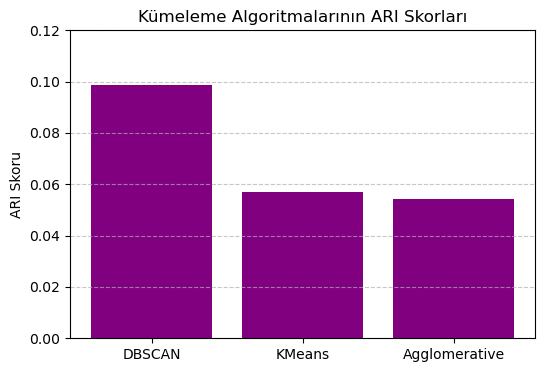

In [155]:
# ARI bar grafiği
plt.figure(figsize=(6,4))
plt.bar(df_ari["Kümeleme Algoritması"], df_ari["ARI Skoru"], color='purple')
plt.title("Kümeleme Algoritmalarının ARI Skorları")
plt.ylabel("ARI Skoru")
plt.ylim(0, 0.12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

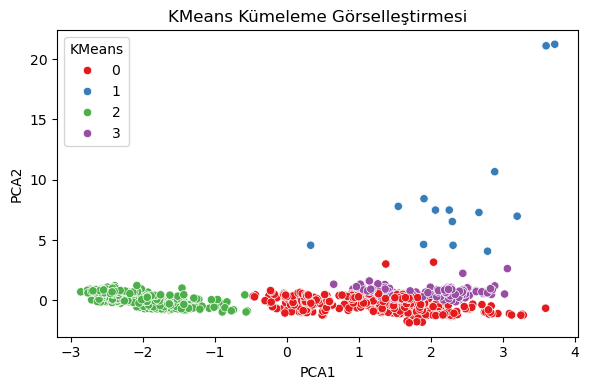

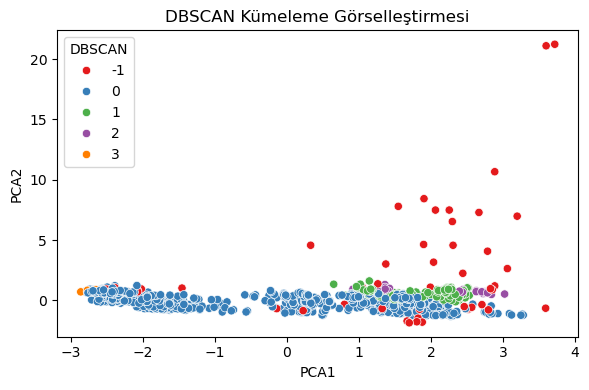

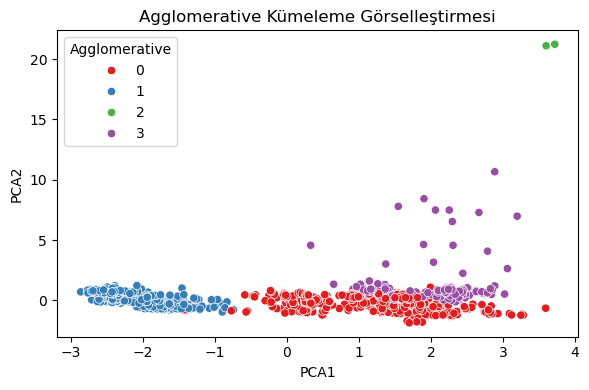

In [156]:
# PCA sonuçlarını birleştir
df_clusters = pd.DataFrame(X_pca, columns=["PCA1", "PCA2"])
for name in results:
    df_clusters[name] = results[name]["Etiketler"]

# her yöntem için grafik
for method in results.keys():
    plt.figure(figsize=(6,4))
    sns.scatterplot(data=df_clusters, x="PCA1", y="PCA2", hue=method, palette="Set1")
    plt.title(f"{method} Kümeleme Görselleştirmesi")
    plt.xlabel("PCA1")
    plt.ylabel("PCA2")
    plt.tight_layout()
    plt.show()